<a href="https://colab.research.google.com/github/Sohail-WD/defect-inspector/blob/feature%2Fvae-detector/VAE_Anomaly_Detection_Bottle.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

from google.colab import drive
drive.mount('/content/drive', force_remount=True)


Mounted at /content/drive


In [2]:

import os

folder = "/content/drive/MyDrive/defect-inspector"

print("Folder exists:", os.path.exists(folder))
print("Files:", os.listdir(folder) if os.path.exists(folder) else "Folder not found")


Folder exists: False
Files: Folder not found


In [3]:

import os

drive_path = "/content/drive/MyDrive"

print("Folders and files in My Drive:\n")

for item in os.listdir(drive_path):
    print(item)


Folders and files in My Drive:

Dandeli 
Shruti_Kushwaha_Resume.docx
Colab Notebooks
defect-inspector-data


In [4]:
import os

folder = "/content/drive/MyDrive/defect-inspector-data"

print("Folder exists:", os.path.exists(folder))
print("Files inside:")

for item in os.listdir(folder):
    print(item)

Folder exists: True
Files inside:
data


In [5]:

import os

data_path = "/content/drive/MyDrive/defect-inspector-data/data"

for root, dirs, files in os.walk(data_path):
    level = root.replace(data_path, "").count(os.sep)

    if level > 3:
        dirs[:] = []
        continue

    print("  " * level + os.path.basename(root) + "/")

    for file in files[:5]:
        print("  " * (level + 1) + file)

    if len(files) > 5:
        print("  " * (level + 1) + f"... and {len(files)-5} more files")


data/
  bottle.tar.xz
  bottle/
    readme.txt
    license.txt
    train/
      good/
        038.png
        019.png
        025.png
        026.png
        035.png
        ... and 204 more files
    ground_truth/
      contamination/
        001_mask.png
        000_mask.png
        014_mask.png
        009_mask.png
        004_mask.png
        ... and 16 more files
      broken_large/
        000_mask.png
        007_mask.png
        001_mask.png
        005_mask.png
        017_mask.png
        ... and 15 more files
      broken_small/
        015_mask.png
        021_mask.png
        012_mask.png
        009_mask.png
        005_mask.png
        ... and 17 more files
    test/
      good/
        007.png
        012.png
        010.png
        005.png
        015.png
        ... and 15 more files
      contamination/
        003.png
        016.png
        007.png
        017.png
        012.png
        ... and 16 more files
      broken_small/
        014.png
        008.png
    

In [6]:

!git clone https://github.com/Sohail-WD/defect-inspector.git

%cd /content/defect-inspector

!pip install -q scipy scikit-learn matplotlib pillow tqdm


Cloning into 'defect-inspector'...
remote: Enumerating objects: 35, done.
remote: Counting objects: 100% (35/35), done.
remote: Compressing objects: 100% (26/26), done.
remote: Total 35 (delta 7), reused 17 (delta 2), pack-reused 0 (from 0)
Receiving objects: 100% (35/35), 2.04 MiB | 4.39 MiB/s, done.
Resolving deltas: 100% (7/7), done.
/content/defect-inspector


In [7]:
import os
import shutil

source = "/content/drive/MyDrive/defect-inspector-data/data/bottle"
destination = "/content/defect-inspector/data/bottle"

os.makedirs("/content/defect-inspector/data", exist_ok=True)

if not os.path.exists(destination):
    shutil.copytree(source, destination)
    print("Dataset copied successfully!")
else:
    print("Dataset already exists in the repository.")

print("Training images:", len(os.listdir(destination + "/train/good")))
print("Test good images:", len(os.listdir(destination + "/test/good")))

Dataset copied successfully!
Training images: 209
Test good images: 20


In [8]:
from data import load_mvtec

d = load_mvtec(size=128)

print("Training:", d["train_images"].shape)
print("Testing:", d["test_images"].shape)
print("Labels:", d["test_labels"].shape)

Training: (209, 128, 128, 3)
Testing: (83, 128, 128, 3)
Labels: (83,)


In [9]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not detected")

PyTorch version: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4


In [11]:
import numpy as np
import torch
from torch.utils.data import DataLoader, TensorDataset

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Use only good training images
train_images = d["train_images"].astype("float32")

# Normalize pixel values from 0–255 to 0–1
if train_images.max() > 1.0:
    train_images = train_images / 255.0

# Convert NHWC to NCHW
train_tensor = torch.tensor(train_images).permute(0, 3, 1, 2)

train_dataset = TensorDataset(train_tensor)

train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

print("Device:", device)
print("Training samples:", len(train_dataset))
print("Batch shape:", next(iter(train_loader))[0].shape)
print("Pixel range:", train_tensor.min().item(), train_tensor.max().item())

Device: cuda
Training samples: 209
Batch shape: torch.Size([16, 3, 128, 128])
Pixel range: 0.11764705926179886 1.0


In [12]:
import torch
import torch.nn as nn

class VAE(nn.Module):
    def __init__(self, latent_dim=128):
        super().__init__()

        # Encoder
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 32, 4, 2, 1),
            nn.ReLU(),

            nn.Conv2d(32, 64, 4, 2, 1),
            nn.ReLU(),

            nn.Conv2d(64, 128, 4, 2, 1),
            nn.ReLU(),

            nn.Conv2d(128, 256, 4, 2, 1),
            nn.ReLU()
        )

        self.fc_mu = nn.Linear(256 * 8 * 8, latent_dim)
        self.fc_logvar = nn.Linear(256 * 8 * 8, latent_dim)

        # Decoder
        self.fc_decode = nn.Linear(latent_dim, 256 * 8 * 8)

        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(256, 128, 4, 2, 1),
            nn.ReLU(),

            nn.ConvTranspose2d(128, 64, 4, 2, 1),
            nn.ReLU(),

            nn.ConvTranspose2d(64, 32, 4, 2, 1),
            nn.ReLU(),

            nn.ConvTranspose2d(32, 3, 4, 2, 1),
            nn.Sigmoid()
        )

    def encode(self, x):
        h = self.encoder(x)
        h = h.reshape(h.size(0), -1)

        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)

        return mu, logvar

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        h = self.fc_decode(z)
        h = h.reshape(-1, 256, 8, 8)
        return self.decoder(h)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        reconstruction = self.decode(z)

        return reconstruction, mu, logvar


model = VAE(latent_dim=128).to(device)

print(model)
print("Model device:", next(model.parameters()).device)

VAE(
  (encoder): Sequential(
    (0): Conv2d(3, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
    (4): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (5): ReLU()
    (6): Conv2d(128, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (7): ReLU()
  )
  (fc_mu): Linear(in_features=16384, out_features=128, bias=True)
  (fc_logvar): Linear(in_features=16384, out_features=128, bias=True)
  (fc_decode): Linear(in_features=128, out_features=16384, bias=True)
  (decoder): Sequential(
    (0): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
    (2): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
    (4): ConvTranspose2d(64, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (5): ReLU()
    (6): ConvTranspose2d(32, 3, kernel_size=(4, 4), stride=(2, 2),

In [13]:
import torch
import torch.nn.functional as F
import torch.optim as optim
import matplotlib.pyplot as plt

optimizer = optim.Adam(model.parameters(), lr=1e-3)

epochs = 300
beta = 1.0

loss_history = []

model.train()

for epoch in range(epochs):
    total_loss = 0
    total_recon = 0
    total_kl = 0

    for (images,) in train_loader:
        images = images.to(device, non_blocking=True)

        optimizer.zero_grad()

        reconstruction, mu, logvar = model(images)

        # Reconstruction loss
        recon_loss = F.mse_loss(
            reconstruction, images, reduction="sum"
        )

        # KL divergence
        kl_loss = -0.5 * torch.sum(
            1 + logvar - mu.pow(2) - logvar.exp()
        )

        # Total loss
        loss = recon_loss + beta * kl_loss

        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        total_recon += recon_loss.item()
        total_kl += kl_loss.item()

    avg_loss = total_loss / len(train_dataset)
    avg_recon = total_recon / len(train_dataset)
    avg_kl = total_kl / len(train_dataset)

    loss_history.append(avg_loss)

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Total: {avg_loss:.2f} | "
            f"Recon: {avg_recon:.2f} | "
            f"KL: {avg_kl:.2f}"
        )

# Save model
save_path = "/content/drive/MyDrive/defect-inspector-data/vae.pt"
torch.save(model.state_dict(), save_path)

print("\nTraining completed!")
print("Model saved at:", save_path)

Epoch [10/300] Total: 161.31 | Recon: 136.45 | KL: 24.86
Epoch [20/300] Total: 142.97 | Recon: 119.51 | KL: 23.46
Epoch [30/300] Total: 122.27 | Recon: 101.08 | KL: 21.18
Epoch [40/300] Total: 111.02 | Recon: 93.39 | KL: 17.64
Epoch [50/300] Total: 102.76 | Recon: 87.61 | KL: 15.16
Epoch [60/300] Total: 96.54 | Recon: 83.71 | KL: 12.83
Epoch [70/300] Total: 95.76 | Recon: 84.71 | KL: 11.05
Epoch [80/300] Total: 96.51 | Recon: 86.90 | KL: 9.61
Epoch [90/300] Total: 88.87 | Recon: 79.98 | KL: 8.89
Epoch [100/300] Total: 91.57 | Recon: 81.93 | KL: 9.64
Epoch [110/300] Total: 88.67 | Recon: 77.99 | KL: 10.69
Epoch [120/300] Total: 86.09 | Recon: 79.28 | KL: 6.81
Epoch [130/300] Total: 82.28 | Recon: 75.41 | KL: 6.87
Epoch [140/300] Total: 84.10 | Recon: 78.65 | KL: 5.45
Epoch [150/300] Total: 82.57 | Recon: 76.87 | KL: 5.70
Epoch [160/300] Total: 81.61 | Recon: 76.74 | KL: 4.87
Epoch [170/300] Total: 81.33 | Recon: 76.59 | KL: 4.73
Epoch [180/300] Total: 89.33 | Recon: 84.41 | KL: 4.92
Epo

RuntimeError: [enforce fail at inline_container.cc:747] . open file failed with strerror: Read-only file system

In [14]:
import torch
import os

local_path = "/content/vae.pt"

torch.save(model.state_dict(), local_path)

print("Model saved:", os.path.exists(local_path))
print("File size:", round(os.path.getsize(local_path) / (1024 * 1024), 2), "MB")

Model saved: True
File size: 29.33 MB


In [15]:
import os

drive_folder = "/content/drive/MyDrive/defect-inspector-data"

print("Drive folder exists:", os.path.exists(drive_folder))
print("Writable:", os.access(drive_folder, os.W_OK))

Drive folder exists: True
Writable: True


In [17]:
import os

print("Model exists:", os.path.exists("/content/vae.pt"))

if os.path.exists("/content/vae.pt"):
    print("Model size:",
          round(os.path.getsize("/content/vae.pt") / (1024 * 1024), 2),
          "MB")

Model exists: True
Model size: 29.33 MB


In [18]:
from google.colab import files

files.download("/content/vae.pt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

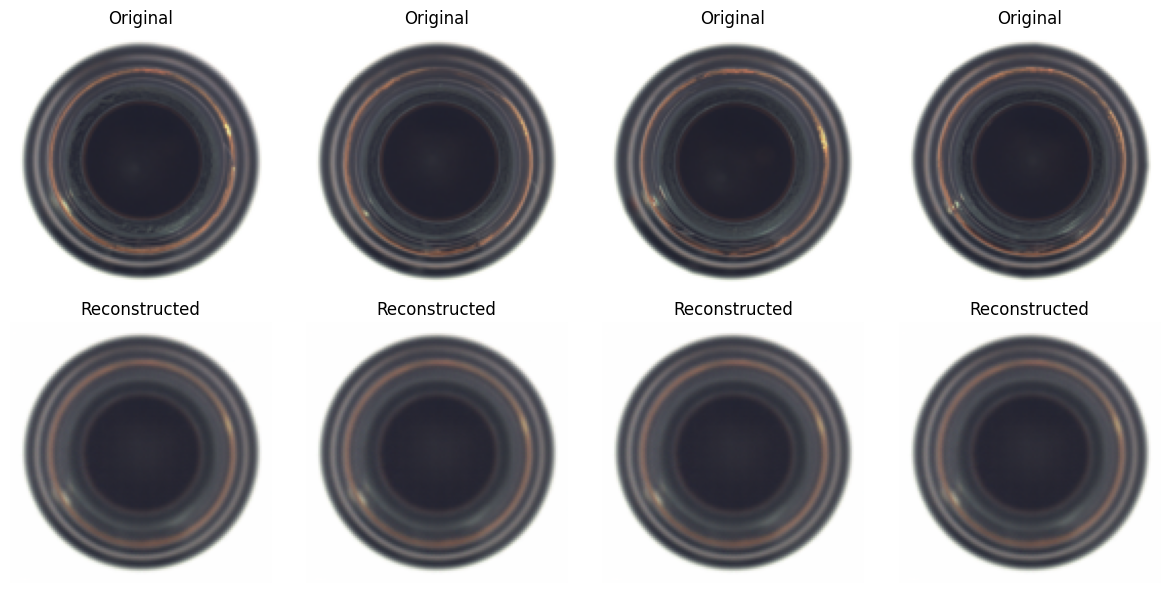

In [19]:
import matplotlib.pyplot as plt
import torch

model.eval()

images = next(iter(train_loader))[0][:4].to(device)

with torch.no_grad():
    mu, logvar = model.encode(images)
    reconstructed = model.decode(mu)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i in range(4):
    original = images[i].cpu().permute(1, 2, 0).numpy()
    redraw = reconstructed[i].cpu().permute(1, 2, 0).numpy()

    axes[0, i].imshow(original)
    axes[0, i].set_title("Original")

    axes[1, i].imshow(redraw)
    axes[1, i].set_title("Reconstructed")

    axes[0, i].axis("off")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

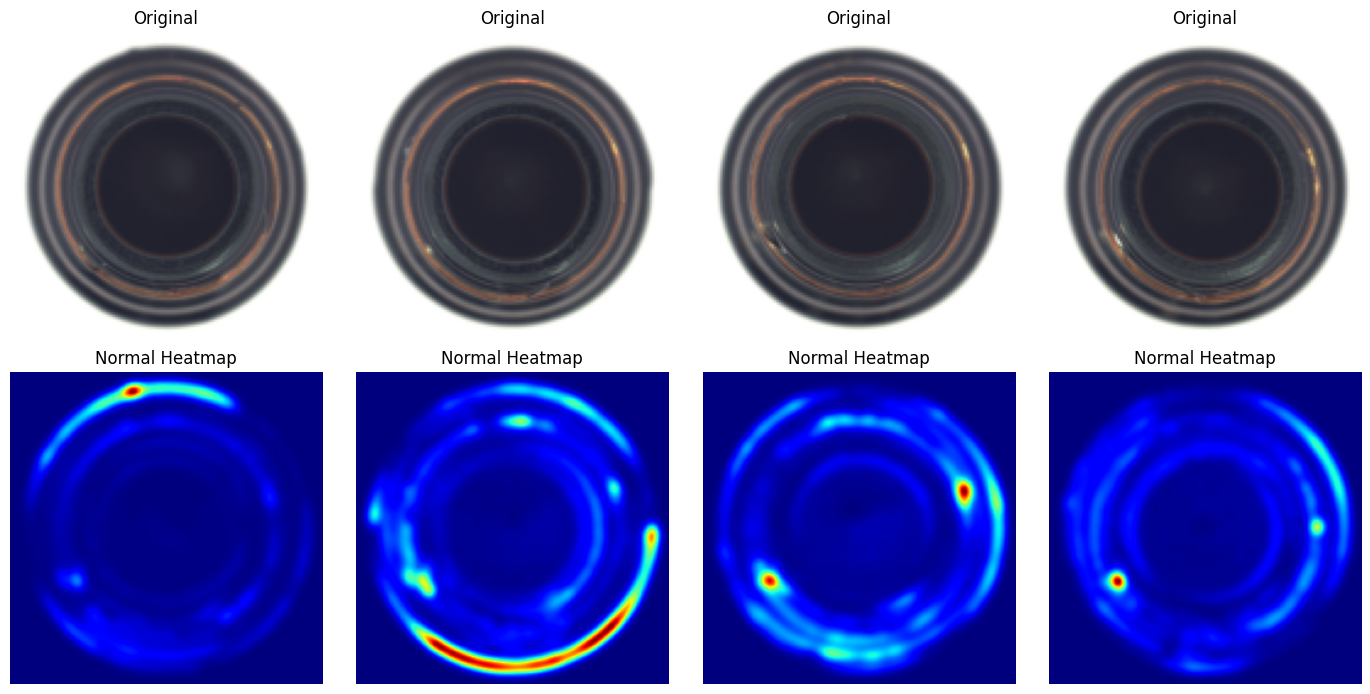

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from scipy.ndimage import gaussian_filter

model.eval()

def get_heatmap(img):
    # img: 128x128x3, values in [0,1]
    x = torch.tensor(img, dtype=torch.float32)
    x = x.permute(2, 0, 1).unsqueeze(0).to(device)

    with torch.no_grad():
        mu, logvar = model.encode(x)
        reconstruction = model.decode(mu)

        error = torch.mean(
            (x - reconstruction) ** 2,
            dim=1,
            keepdim=True
        )

        error = F.interpolate(
            error,
            size=(256, 256),
            mode="bilinear",
            align_corners=False
        )

    heatmap = error.squeeze().cpu().numpy()
    heatmap = gaussian_filter(heatmap, sigma=4)

    return heatmap


# Display heatmaps for four normal training images
fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for i in range(4):
    img = train_images[i]
    heatmap = get_heatmap(img)

    axes[0, i].imshow(img)
    axes[0, i].set_title("Original")

    axes[1, i].imshow(heatmap, cmap="jet")
    axes[1, i].set_title("Normal Heatmap")

    axes[0, i].axis("off")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

In [21]:
print("Dataset keys:", d.keys())

print("\nTest images:", d["test_images"].shape)
print("Test labels:", d["test_labels"].shape)

import numpy as np

labels, counts = np.unique(d["test_labels"], return_counts=True)

print("\nLabel distribution:")
for label, count in zip(labels, counts):
    print(label, ":", count)

Dataset keys: dict_keys(['train_images', 'test_images', 'test_labels', 'test_masks', 'test_types', 'test_paths'])

Test images: (83, 128, 128, 3)
Test labels: (83,)

Label distribution:
0 : 20
1 : 63


Normal image: 63
Defective image: 0
Defect type: broken_large


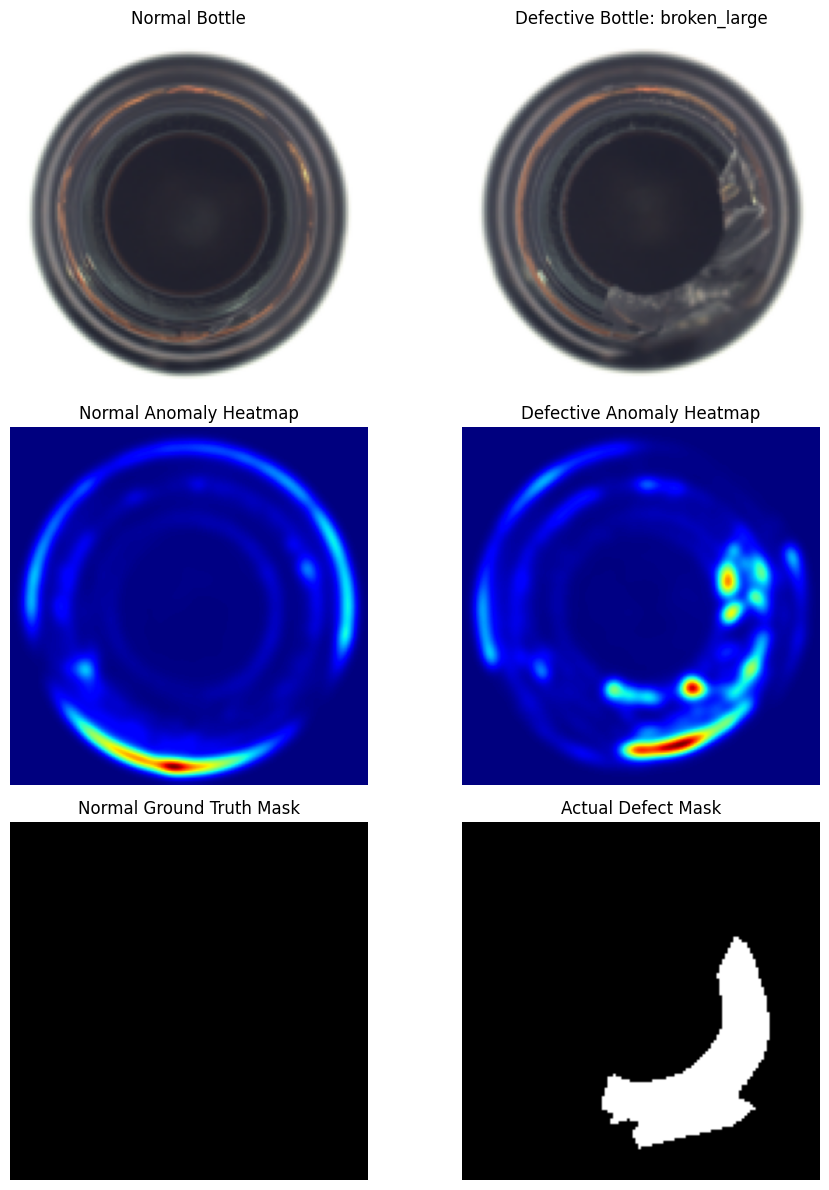

In [22]:
import numpy as np
import matplotlib.pyplot as plt

# Prepare test images
test_images = d["test_images"].astype("float32")

if test_images.max() > 1.0:
    test_images = test_images / 255.0

test_labels = d["test_labels"]
test_masks = d["test_masks"]
test_types = d["test_types"]

# Find one normal and one defective image
normal_idx = np.where(test_labels == 0)[0][0]
defect_idx = np.where(test_labels == 1)[0][0]

print("Normal image:", normal_idx)
print("Defective image:", defect_idx)
print("Defect type:", test_types[defect_idx])

# Generate heatmaps
normal_heatmap = get_heatmap(test_images[normal_idx])
defect_heatmap = get_heatmap(test_images[defect_idx])

# Display comparison
fig, axes = plt.subplots(3, 2, figsize=(10, 12))

# Original images
axes[0, 0].imshow(test_images[normal_idx])
axes[0, 0].set_title("Normal Bottle")

axes[0, 1].imshow(test_images[defect_idx])
axes[0, 1].set_title(f"Defective Bottle: {test_types[defect_idx]}")

# VAE heatmaps
axes[1, 0].imshow(normal_heatmap, cmap="jet")
axes[1, 0].set_title("Normal Anomaly Heatmap")

axes[1, 1].imshow(defect_heatmap, cmap="jet")
axes[1, 1].set_title("Defective Anomaly Heatmap")

# Actual ground-truth masks
axes[2, 0].imshow(test_masks[normal_idx], cmap="gray")
axes[2, 0].set_title("Normal Ground Truth Mask")

axes[2, 1].imshow(test_masks[defect_idx], cmap="gray")
axes[2, 1].set_title("Actual Defect Mask")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [23]:
import numpy as np
import torch
import torch.nn.functional as F
from sklearn.metrics import roc_auc_score
from tqdm.notebook import tqdm

model.eval()

image_scores = []
all_heatmaps = []

# Generate heatmaps for all 83 test images
for img in tqdm(test_images):
    heatmap = get_heatmap(img)

    all_heatmaps.append(heatmap)

    # Maximum anomaly score for each image
    image_scores.append(np.max(heatmap))

all_heatmaps = np.array(all_heatmaps)
image_scores = np.array(image_scores)

# Image-level AUROC
image_auc = roc_auc_score(test_labels, image_scores)

print("Image AUROC:", round(image_auc, 4))
print("Heatmap shape:", all_heatmaps.shape)

  0%|          | 0/83 [00:00<?, ?it/s]

Image AUROC: 0.8802
Heatmap shape: (83, 256, 256)


In [24]:
# Convert ground-truth masks to binary format
masks = np.asarray(test_masks)

if masks.ndim == 4 and masks.shape[-1] == 1:
    masks = masks[..., 0]

if masks.ndim == 4 and masks.shape[1] == 1:
    masks = masks[:, 0]

# Resize heatmaps to mask dimensions if necessary
heatmap_tensor = torch.tensor(
    all_heatmaps, dtype=torch.float32
).unsqueeze(1)

heatmap_resized = F.interpolate(
    heatmap_tensor,
    size=masks.shape[1:3],
    mode="bilinear",
    align_corners=False
).squeeze(1).numpy()

binary_masks = (masks > 0).astype(np.uint8)

pixel_auc = roc_auc_score(
    binary_masks.ravel(),
    heatmap_resized.ravel()
)

print("Pixel AUROC:", round(pixel_auc, 4))

Pixel AUROC: 0.8443


In [25]:
from sklearn.metrics import roc_auc_score

image_auc = roc_auc_score(test_labels, image_scores)

print("Image AUROC:", round(image_auc, 4))

Image AUROC: 0.8802


In [26]:
print("========== VAE FINAL RESULTS ==========")

print("Training images:", len(d["train_images"]))
print("Normal test images:", np.sum(d["test_labels"] == 0))
print("Defective test images:", np.sum(d["test_labels"] == 1))

print("---------------------------------------")
print("Image AUROC:", round(image_auc, 4))
print("Pixel AUROC:", round(pixel_auc, 4))

print("=======================================")

========== VAE FINAL RESULTS ==========
Training images: 209
Normal test images: 20
Defective test images: 63
---------------------------------------
Image AUROC: 0.8802
Pixel AUROC: 0.8443


### VAE Detector – Experimental Results

The Variational Autoencoder (VAE) was trained on 209 defect-free bottle images from the MVTec AD dataset. The model was trained for 300 epochs using a latent dimension of 128, batch size of 16, Adam optimizer, and learning rate of 0.001.

The trained VAE reconstructs normal bottle images and uses pixel-wise reconstruction error to generate anomaly heatmaps.

**Evaluation results:**
- Image AUROC: 0.8802
- Pixel AUROC: 0.8443

The results indicate promising image-level anomaly detection and pixel-level defect localization. Visual inspection showed that the model responds to some defective regions, although normal reflections and bottle edges can also produce false-positive heatmap responses.

The model was trained exclusively on good bottle images, without using defective test images during training.